In [1]:
import sklearn
from sklearn.model_selection import train_test_split
import sqlite3
import pandas as pd
import seaborn as sns
import scipy
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("tips.csv")
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [3]:
X = df[["total_bill"]]
y = df["tip"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [4]:
len(X_train)

170

We grade on the data the model never saw to make sure it doesn't simply memorize the answers. It must train on some practice data sets, and some data sets must be saved for last after the model learns the underlying patterns of the data.

In [5]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print(model.score(X_test, y_test))
print(model.coef_, model.intercept_)

0.4291782688312412
[0.10889371] 0.8769576391532699


Each extra dollar of bill adds about 0.10 of tip.

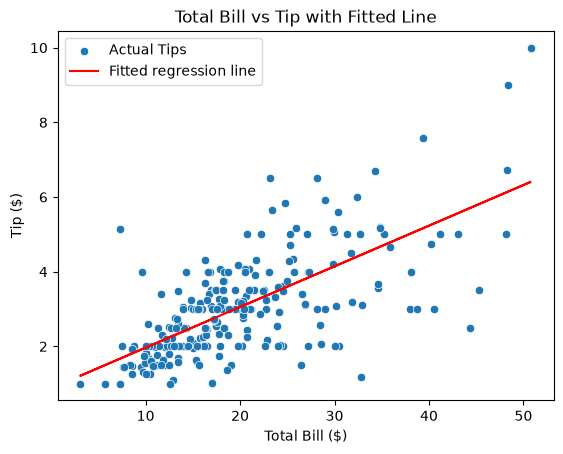

In [6]:
prediction = model.predict(X)
sns.scatterplot(data=df, x="total_bill", y="tip", label="Actual Tips")
plt.plot(X["total_bill"], prediction, color="red", label="Fitted regression line")
plt.title("Total Bill vs Tip with Fitted Line")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.legend()
plt.show()

In [7]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [8]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (105, 4)
X_test: (45, 4)


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_scores = knn.score(X_test, y_test)
print("Test scores:", knn_scores)

Test scores: 1.0


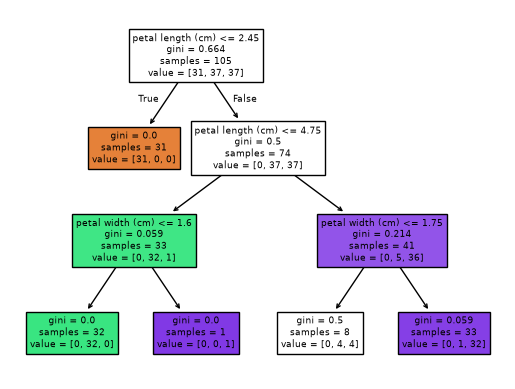

In [10]:
tree = DecisionTreeClassifier(random_state=42, max_depth=3)
tree.fit(X_train, y_train)
tree_score = tree.score(X_test, y_test)
tree_train_score = tree.score(X_train, y_train)

from sklearn.tree import plot_tree
plot_tree(tree, feature_names=X.columns, filled=True)
plt.show()

The root split checks whether the petal width is less than or equal to 0.8 cm. If true, it splits to the left branch, and if false, it splits to the right branch.

In [11]:
unlim_tree = DecisionTreeClassifier(random_state=42)
unlim_tree.fit(X_train, y_train)
unlim_tree_test_score = unlim_tree.score(X_test, y_test)
unlim_tree_train_score = unlim_tree.score(X_train, y_train)

print(f"Shallow tree's test score: {tree_score}, shallow tree's train score: {tree_train_score}")
print(f"Unlimited tree's test score: {unlim_tree_test_score}, unlimited tree's train score: {unlim_tree_train_score}")

Shallow tree's test score: 1.0, shallow tree's train score: 0.9523809523809523
Unlimited tree's test score: 1.0, unlimited tree's train score: 1.0


I'm observing that both shallow and unlimited trees score 1.0 on test, but unlimited tree scores 1.0 on train scores whereas the shallow tree scores 0.95238 on the train score.

In [12]:
new_flower = pd.DataFrame({
    "sepal length (cm)": [4.6],
    "sepal width (cm)": [1.2],
    "petal length (cm)": [8.3],
    "petal width (cm)": [0.5]
})

prediction = unlim_tree.predict(new_flower)
print(iris.target_names[prediction])

['virginica']


A predicted class name for my invented flower is "Virginica."

With the invention of my flower of sepal length 4.6cm, sepal width 1.2cm, petal length 8.3cm, and petal width 0.5cm, it predicted that I would get a Virginica for the class name based on the unlimited tree's prediction. I would ship the unlimited tree along its test score, since it scored 100% accuracy. The shallow tree's max depth most likely caused its train score to achieve 95% accuracy, so I would choose the unlimited tree. A scenario where it might fail could be where there's millions of sample data, so going through all of them in the tree could be super complex and possibly lead to overfitting. One bias risk if this were a model about people instead of flowers could be that the model could generalize poorly due to noise and overfitting. It could also become incredibly hard to interpret and read data, since the tree itself is huge and complex.

Repo address: https://github.com/yeonghwang-hub/cs82a-portfolio